# 00. 공통 파이프라인 (A·B·C 공용)

이 노트북은 **0~3단계**(데이터 확보, 정제, 기준일 분할)를 `rfm_utils.py`로 실행하고 결과를 확인한다.
B와 C는 자기 노트북에서 아래 세 줄만 똑같이 쓰면 같은 고객, 같은 기준일, 같은 라벨에서 출발한다.

```python
inv = ru.invoice_table(ru.clean_transactions(ru.load_raw())[0])
data = ru.make_dataset(inv, ru.SNAPSHOTS["S2"])
ru.assert_no_leakage(inv, data, ru.SNAPSHOTS["S2"])
```

**규칙 하나:** 특징(R, F, M)은 기준일 **이전** 주문만, 정답(재구매)은 기준일 **이후 90일** 주문만 쓴다.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))  # the notebook lives in notebooks/
import rfm_utils as ru

np.random.seed(ru.SEED)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. 데이터 불러오기

처음 실행하면 UCI에서 원본(xlsx, 약 46MB)을 내려받고 읽어서 `data/` 폴더에 gzip CSV로 캐시한다. 이후에는 캐시만 읽는다.
`data/`는 `.gitignore`에 들어 있어 저장소에 올라가지 않는다. 재배포 조건은 UCI 페이지에서 확인한다.

In [2]:
raw = ru.load_raw()
print(raw.shape)
raw.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


## 2. 정제와 정제 보고서

규칙은 `clean_transactions`의 docstring에 적혀 있다. 아래 표는 규칙마다 몇 행이 사라지는지 보여 준다.
완전 중복 행(3% 정도)을 지울지는 **팀이 이 표를 보고 정한다.** 기본값은 지우는 쪽이다.

In [3]:
clean, report = ru.clean_transactions(raw)
report

,step,rows
0,raw rows,1067371
1,removed: cancellations (invoice starts with C),19494
2,removed: missing customer id,242257
3,removed: quantity <= 0 or price <= 0,71
4,"removed: non-product lines (postage, fees, man...",2915
5,removed: exact duplicate rows,26055
6,clean rows,776579


In [4]:
inv = ru.invoice_table(clean)
print(inv.shape, "- one row per (customer, invoice); columns:", list(inv.columns))
print("customers:", inv["customer_id"].nunique())
print("date range:", inv["invoice_date"].min(), "->", inv["invoice_date"].max())
inv.head()

(36594, 4) - one row per (customer, invoice); columns: ['customer_id', 'invoice', 'invoice_date', 'amount']
customers: 5852
date range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


,customer_id,invoice,invoice_date,amount
0,12346,499763,2010-03-02 13:08:00,27.05
1,12346,513774,2010-06-28 13:53:00,142.31
2,12346,541431,2011-01-18 10:01:00,"77,183.60"
3,12347,529924,2010-10-31 14:20:00,611.53
4,12347,537626,2010-12-07 14:57:00,711.79


## 3. 기준일별 데이터셋

세 기준일마다 `make_dataset`이 고객당 한 행을 만든다. 컬럼은 `R, F, M, avg_order_value, T, recency_bgnbd,
frequency_bgnbd, repeat_avg_amount`(특징)와 `repurchase, future_orders, future_revenue`(정답)다.

In [5]:
datasets = {name: ru.make_dataset(inv, date) for name, date in ru.SNAPSHOTS.items()}

summary = pd.DataFrame({
    name: {
        "snapshot": ru.SNAPSHOTS[name],
        "customers with history": len(d),
        "repurchasers": int(d["repurchase"].sum()),
        "repurchase rate": d["repurchase"].mean(),
    }
    for name, d in datasets.items()
}).T
summary

,snapshot,customers with history,repurchasers,repurchase rate
S1,2011-03-01,4512,1585,0.35
S2,2011-06-01,4908,1617,0.33
S3,2011-09-01,5224,2236,0.43


## 4. 누수 점검

`assert_no_leakage`는 R과 F를 기준일 이전 주문만으로 처음부터 다시 계산해 데이터셋과 비교한다.
통과하지 못하면 AssertionError가 난다. **새 노트북에서 데이터셋을 만들 때마다 호출한다.**

In [6]:
for name, d in datasets.items():
    ru.assert_no_leakage(inv, d, ru.SNAPSHOTS[name])
    print(name, "ok")

# The label window must not run past the end of the data:
try:
    ru.build_labels(inv, "2011-10-15")
except ValueError as e:
    print("expected error ->", e)

S1 ok
S2 ok
S3 ok
expected error -> Label window [2011-10-15, 2012-01-13) goes past the data end (2011-12-09 12:50:00). Choose an earlier snapshot.


## 5. 기준선: "최근에 샀는가"만 쓰면 얼마나 잘 맞히나

모든 방법은 이 기준선(`-R` 점수)보다 나아야 의미가 있다(H3). 아래는 최근성(R)을 5분위로 나눈 재구매율과,
상위 10%만 연락했을 때의 효율(lift@10%)이다.

,mean,size
R_quintile,,
1 most recent,0.66,983
2,0.47,993
3,0.28,981
4,0.15,970
5 oldest,0.09,981


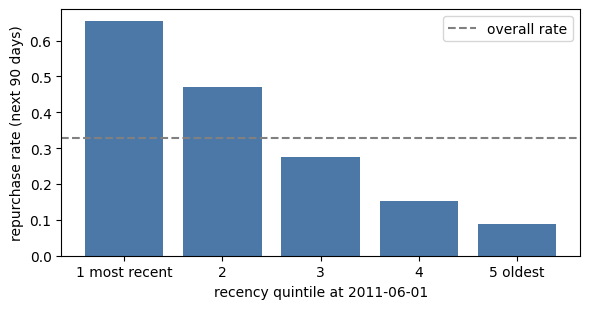

In [7]:
d = datasets["S2"].copy()
d["R_quintile"] = pd.qcut(d["R"], 5, labels=["1 most recent", "2", "3", "4", "5 oldest"])
by_q = d.groupby("R_quintile", observed=True)["repurchase"].agg(["mean", "size"])
display(by_q)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(by_q.index.astype(str), by_q["mean"], color="#4c78a8")
ax.axhline(d["repurchase"].mean(), color="gray", ls="--", label="overall rate")
ax.set_ylabel("repurchase rate (next 90 days)")
ax.set_xlabel("recency quintile at 2011-06-01")
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
rows = []
for name, d in datasets.items():
    res = ru.lift_at_k(d["repurchase"], ru.baseline_recency_score(d), k=0.10)
    rows.append({"snapshot": name, **res})
pd.DataFrame(rows).set_index("snapshot")

,capture,precision,lift
snapshot,,,
S1,0.19,0.68,1.94
S2,0.20,0.67,2.02
S3,0.18,0.76,1.78


## 6. 점수 표 형식 (세 방법이 모두 따를 것)

모든 방법은 `(customer_id, snapshot, method, score)` 형식으로 점수를 낸다. 점수가 높을수록 재구매 가능성이 높다.
이 형식이면 A의 평가 코드가 방법에 상관없이 똑같이 돌아간다.

In [9]:
d = datasets["S2"]
scores = ru.to_score_frame(d.index, ru.baseline_recency_score(d), ru.SNAPSHOTS["S2"], "recency_only")
ru.validate_score_frame(scores, d)   # raises AssertionError if something is off
scores.head()

,customer_id,snapshot,method,score
0,12346,2011-06-01,recency_only,-133.00
1,12347,2011-06-01,recency_only,-54.00
2,12348,2011-06-01,recency_only,-56.00
3,12349,2011-06-01,recency_only,-215.00
4,12350,2011-06-01,recency_only,-118.00


## 다음 단계

- **A:** EDA(분포, 파레토, 코호트)와 평가 프레임(gain/lift 곡선, 예산 시뮬레이션)
- **B:** 규칙 기반 RFM 점수와 세그먼트, K-means, H1·H2
- **C:** 로지스틱·트리 모델, BG/NBD

각자 `notebooks/` 안에 자기 노트북을 만들고, 공용 함수를 고칠 일이 생기면 `rfm_utils.py`만 고친 뒤 단톡방에 알린다.